# Question 1: Can property characteristics predict sale prices more accurately than neighborhood-level price estimates?

**Decision-maker:** real estate investors and property assessors who want price estimates to flag properties worth a closer valuation or investment review.

**Approach (frozen in QUESTIONS.md):** compare a **neighborhood-median baseline** with supervised regression models using **5-fold cross-validation** on `train.csv`. Neighborhood medians and all preprocessing are fitted on the training part of each fold only. We report MAE, RMSE, and R² (mean ± SD across folds).

`test.csv` has no `SalePrice`, so it cannot be used to score models; it is **never loaded** here. Final performance claims rest on cross-validation, which is a stated limitation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import GradientBoostingRegressor

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# Data: place train.csv in ../data/ (same layout as the EDA notebook)
for p in [Path("../data/train.csv"), Path("data/train.csv"), Path("train.csv")]:
    if p.exists():
        DATA_PATH = p
        break
train = pd.read_csv(DATA_PATH)
price = train["SalePrice"].values
y = np.log(price)          # models are fit on log price (target is right-skewed)
print(train.shape)

(1460, 81)


## 1. Target

Sale price is right-skewed, and errors on expensive homes are naturally larger in dollars. We fit every model (and the baselines) on **log price**, so the model treats errors as percentages. Predictions are converted back to dollars before computing MAE, RMSE, and R², so all reported metrics are in dollars as the decision-maker would see them.

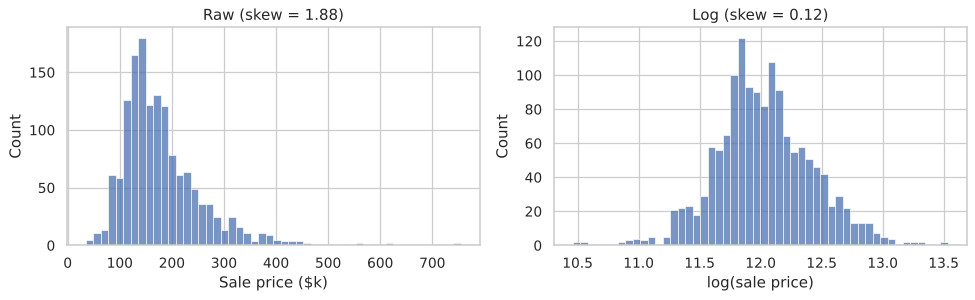

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(price / 1000, bins=50, ax=ax[0]); ax[0].set(xlabel="Sale price ($k)", title=f"Raw (skew = {pd.Series(price).skew():.2f})")
sns.histplot(y, bins=50, ax=ax[1]); ax[1].set(xlabel="log(sale price)", title=f"Log (skew = {pd.Series(y).skew():.2f})")
plt.tight_layout(); plt.show()

## 2. Features

**Property characteristics** = everything that describes the house and lot. Excluded:
- `Id`, `SalePrice` – identifier and target.
- **Location:** `Neighborhood`, `MSZoning`, `Condition1`, `Condition2`. These belong to the baseline's information, so the main model is a clean "characteristics vs. location" test. A second model adds location back to see if the two combine.
- **Sale transaction:** `MoSold`, `YrSold`, `SaleType`, `SaleCondition`. They describe the sale, not the property, and `SaleCondition` would not be known when assessing a home before it sells. (`YrSold` is used only to compute house age.)

**Missingness as information:** NA in quality and type columns means "feature absent" (no garage, no basement, no pool). Ordinal quality codes (Po < Fa < TA < Gd < Ex) are mapped to 1–5, with absent = 0, so the order is kept. Categorical NAs become their own level `"None"`. Only `LotFrontage`, `MasVnrArea`, and `GarageYrBlt` have true unknowns; these are imputed with the training-fold median.

In [3]:
qual_map = {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ordinal_cols = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual",
                "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
LOCATION = ["Neighborhood", "MSZoning", "Condition1", "Condition2"]
SALE = ["MoSold", "YrSold", "SaleType", "SaleCondition"]

def build_features(df):
    X = df.drop(columns=["Id", "SalePrice"]).copy()
    for c in ordinal_cols:
        X[c] = X[c].map(qual_map).fillna(0)          # NA = feature absent -> 0
    X["TotalSF"] = X["TotalBsmtSF"] + X["1stFlrSF"] + X["2ndFlrSF"]
    X["TotalBath"] = X["FullBath"] + 0.5*X["HalfBath"] + X["BsmtFullBath"] + 0.5*X["BsmtHalfBath"]
    X["HouseAge"] = X["YrSold"] - X["YearBuilt"]
    X["YearsSinceRemodel"] = X["YrSold"] - X["YearRemodAdd"]
    for c in ["GrLivArea", "LotArea", "TotalSF", "1stFlrSF"]:
        X[c] = np.log1p(X[c])                        # reduce skew of large areas
    X["MSSubClass"] = X["MSSubClass"].astype(str)    # dwelling-type code, not a quantity
    return X.drop(columns=SALE)

X_all = build_features(train)
X_prop = X_all.drop(columns=LOCATION)
print("Property-only features:", X_prop.shape[1], "| with location:", X_all.shape[1])

Property-only features: 75 | with location: 79


In [4]:
def make_model(X, estimator):
    cats = X.select_dtypes("object").columns.tolist()
    nums = [c for c in X.columns if c not in cats]
    pre = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), nums),
        ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"),
                              OneHotEncoder(handle_unknown="ignore", min_frequency=10)), cats),
    ])
    return make_pipeline(pre, estimator)

ridge = lambda: RidgeCV(alphas=np.logspace(-2, 3, 30))   # alpha picked by internal CV on the training fold only
gbr = lambda: GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=3,
                                        subsample=0.8, random_state=SEED)

## 3. Models and baselines

| Name | What it uses | Why it is here |
|---|---|---|
| Overall median | nothing | floor: any method must beat this |
| **Neighborhood median** | neighborhood only | **the baseline the question asks about** |
| Ridge (characteristics) | property characteristics | interpretable linear model; regularization handles ~200 correlated one-hot/numeric columns |
| Gradient boosting (characteristics) | property characteristics | captures non-linear effects and interactions (e.g., quality × size) that a linear model misses |
| Gradient boosting (characteristics + location) | both | does location add anything on top of characteristics? |

The ridge penalty is chosen by efficient leave-one-out CV inside each training fold. Gradient-boosting settings are standard, untuned defaults (500 trees, depth 3, learning rate 0.05). Tuning them on the same folds we report would bias the comparison toward the model, so leaving them untuned is conservative.

In [5]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(kf.split(X_all))
nbhd = train["Neighborhood"].values

def fold_metrics(actual, pred):
    err = actual - pred
    return {"MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err**2)),
            "R2": 1 - np.sum(err**2) / np.sum((actual - actual.mean())**2),
            "MedAPE_%": np.median(np.abs(err) / actual) * 100}

def cross_validate(predict_fn, train_mask=None):
    """predict_fn(tr, te) -> log-price predictions for te. Returns per-fold metrics and out-of-fold predictions."""
    rows, oof = [], np.zeros(len(y))
    for k, (tr, te) in enumerate(folds):
        if train_mask is not None:
            tr = tr[train_mask[tr]]
        p = predict_fn(tr, te)
        oof[te] = np.exp(p)
        rows.append({"fold": k, **fold_metrics(price[te], np.exp(p))})
    return pd.DataFrame(rows), oof

def overall_median(tr, te):
    return np.full(len(te), np.median(y[tr]))

def neighborhood_median(tr, te):
    med = pd.Series(y[tr]).groupby(nbhd[tr]).median()        # training fold only
    return pd.Series(nbhd[te]).map(med).fillna(np.median(y[tr])).values

def model_fn(X, est):
    return lambda tr, te: make_model(X, est()).fit(X.iloc[tr], y[tr]).predict(X.iloc[te])

methods = {
    "Overall median":                  overall_median,
    "Neighborhood median (baseline)":  neighborhood_median,
    "Ridge – characteristics":         model_fn(X_prop, ridge),
    "GBoost – characteristics":        model_fn(X_prop, gbr),
    "GBoost – characteristics + location": model_fn(X_all, gbr),
}
cv, oof = {}, {}
for name, fn in methods.items():
    cv[name], oof[name] = cross_validate(fn)

def summarize(cv):
    s = pd.DataFrame({n: d.drop(columns="fold").agg(["mean", "std"]).unstack() for n, d in cv.items()}).T
    s.columns = [f"{m} {stat}" for m, stat in s.columns]
    return s
summary = summarize(cv)
display(summary[["MAE mean", "MAE std", "RMSE mean", "RMSE std", "R2 mean", "R2 std", "MedAPE_% mean"]].round(3))

,MAE mean,MAE std,RMSE mean,RMSE std,R2 mean,R2 std,MedAPE_% mean
Overall median,55655.518,3169.624,81275.336,5929.009,-0.054,0.024,24.820
Neighborhood median (baseline),36230.841,1443.418,55267.418,3155.350,0.511,0.028,14.731
Ridge – characteristics,17247.555,2671.962,41058.279,30665.664,0.577,0.686,6.400
GBoost – characteristics,15741.894,1457.373,28917.006,9318.657,0.850,0.120,5.867
GBoost – characteristics + location,14758.151,1659.503,27805.454,9966.413,0.858,0.125,5.453


**Note on the Ridge RMSE spread:** Ridge's RMSE and R² vary a lot across folds. The next cell shows the cause: one home.

In [6]:
big = train["GrLivArea"] > 4000
display(train.loc[big, ["Id", "GrLivArea", "SalePrice", "SaleCondition", "Neighborhood"]]
        .assign(ridge_pred=oof["Ridge – characteristics"][big].round(0),
                gboost_pred=oof["GBoost – characteristics"][big].round(0)))

,Id,GrLivArea,SalePrice,SaleCondition,Neighborhood,ridge_pred,gboost_pred
523,524,4676,184750,Partial,Edwards,841666.0,706542.0
691,692,4316,755000,Normal,NoRidge,551059.0,545024.0
1182,1183,4476,745000,Abnorml,NoRidge,349319.0,541593.0
1298,1299,5642,160000,Partial,Edwards,1611660.0,588000.0


Two very large homes in Edwards (Ids 524 and 1299) sold as **partial sales** for far less than their size implies. The dataset's author (De Cock, 2011) flags homes over 4,000 sq ft as unusual sales and recommends removing them. A linear model in log space extrapolates far beyond the data for these homes. After converting back to dollars, a single prediction of about $1.7M for a $160k home dominates a fold's RMSE. Trees cannot extrapolate beyond the training range, so gradient boosting is hurt much less (≈\$588k predicted). That one home still explains most of its R² spread across folds.

We **keep all homes** in the main results above, because deleting hard cases would flatter the model. Section 5 reports the same comparison with those 4 homes removed from training and scoring.

## 4. Does the model beat the baseline in every fold?

,baseline MAE,GBoost MAE,Ridge MAE,GBoost improvement %
0,37202.0,16587.0,17267.0,55.0
1,37771.0,14329.0,16682.0,62.0
2,35078.0,17587.0,21620.0,50.0
3,36727.0,15987.0,16283.0,56.0
4,34376.0,14219.0,14386.0,59.0


Homes where GBoost (characteristics) is closer than the neighborhood median: 74.7%


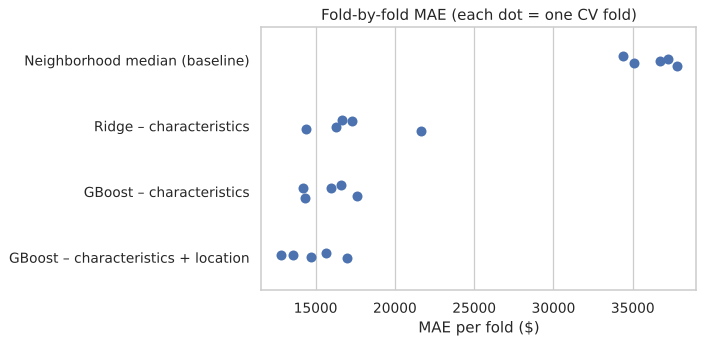

In [7]:
base = cv["Neighborhood median (baseline)"]
paired = pd.DataFrame({
    "baseline MAE": base["MAE"],
    "GBoost MAE": cv["GBoost – characteristics"]["MAE"],
    "Ridge MAE": cv["Ridge – characteristics"]["MAE"],
})
paired["GBoost improvement %"] = (1 - paired["GBoost MAE"] / paired["baseline MAE"]) * 100
display(paired.round(0))

closer = np.abs(oof["GBoost – characteristics"] - price) < np.abs(oof["Neighborhood median (baseline)"] - price)
print(f"Homes where GBoost (characteristics) is closer than the neighborhood median: {closer.mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
names_plot = ["Neighborhood median (baseline)", "Ridge – characteristics", "GBoost – characteristics",
              "GBoost – characteristics + location"]
sns.stripplot(data=pd.concat([cv[n].assign(method=n) for n in names_plot]), y="method", x="MAE", size=8, ax=ax)
ax.set(xlabel="MAE per fold ($)", ylabel="", title="Fold-by-fold MAE (each dot = one CV fold)")
plt.tight_layout(); plt.show()

## 5. Sensitivity: excluding the 4 homes over 4,000 sq ft

In [8]:
keep = ~big.values
def cv_subset(fn):
    rows = []
    for k, (tr, te) in enumerate(folds):
        tr, te = tr[keep[tr]], te[keep[te]]
        rows.append({"fold": k, **fold_metrics(price[te], np.exp(fn(tr, te)))})
    return pd.DataFrame(rows)

cv_trim = {n: cv_subset(fn) for n, fn in methods.items()}
summary_trim = summarize(cv_trim)
display(summary_trim[["MAE mean", "MAE std", "RMSE mean", "RMSE std", "R2 mean", "R2 std"]].round(3))

,MAE mean,MAE std,RMSE mean,RMSE std,R2 mean,R2 std
Overall median,54982.917,2580.210,78591.984,2940.061,-0.054,0.025
Neighborhood median (baseline),35601.187,933.610,52745.518,1746.017,0.524,0.042
Ridge – characteristics,14714.739,834.458,21893.243,2363.470,0.918,0.012
GBoost – characteristics,14556.058,1101.414,22344.876,2703.994,0.914,0.017
GBoost – characteristics + location,13915.716,877.665,21536.526,2520.608,0.920,0.015


With the unusual sales removed, Ridge becomes stable and close to gradient boosting. The conclusion does not change: both characteristic-based models clearly beat the neighborhood median.

## 6. Where does the improvement come from?

The EDA showed that some neighborhoods have much more price variation than others. If characteristics matter, the model's gain over the baseline should be largest where a single neighborhood median describes homes poorly.

,n,baseline_MedAPE,model_MedAPE,price_CV,gain_pts
Neighborhood,,,,,
StoneBr,25,28.1,6.2,0.4,21.9
Veenker,11,26.5,6.0,0.3,20.6
SawyerW,59,21.2,2.7,0.3,18.5
Blueste,2,19.8,2.3,0.1,17.5
Timber,38,22.3,7.9,0.3,14.4
NridgHt,77,19.7,5.6,0.3,14.0
CollgCr,150,15.4,3.8,0.3,11.6
Somerst,86,16.4,4.9,0.2,11.5
IDOTRR,37,20.4,9.0,0.3,11.4


Neighborhoods where the model is better: 25 of 25
Correlation between within-neighborhood price variability and model gain: 0.43


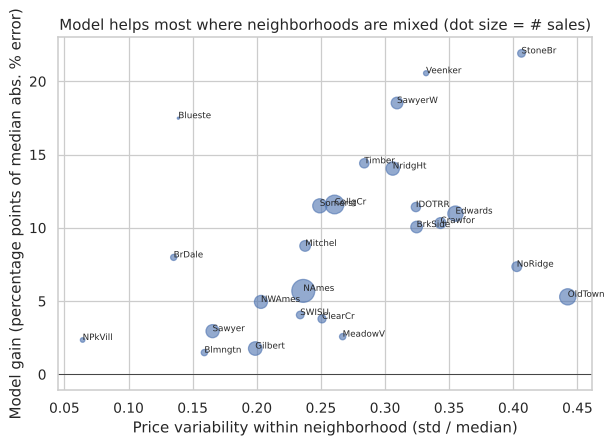

In [9]:
err = pd.DataFrame({
    "Neighborhood": nbhd,
    "base_ape": np.abs(oof["Neighborhood median (baseline)"] - price) / price * 100,
    "model_ape": np.abs(oof["GBoost – characteristics"] - price) / price * 100,
})
by_n = err.groupby("Neighborhood").agg(n=("base_ape", "size"), baseline_MedAPE=("base_ape", "median"),
                                       model_MedAPE=("model_ape", "median"))
by_n["price_CV"] = train.groupby("Neighborhood")["SalePrice"].agg(lambda s: s.std() / s.median())
by_n["gain_pts"] = by_n["baseline_MedAPE"] - by_n["model_MedAPE"]
by_n = by_n.sort_values("gain_pts", ascending=False)
display(by_n.round(1))
print("Neighborhoods where the model is better:", (by_n["gain_pts"] > 0).sum(), "of", len(by_n))
print("Correlation between within-neighborhood price variability and model gain:",
      round(by_n["price_CV"].corr(by_n["gain_pts"]), 2))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(by_n["price_CV"], by_n["gain_pts"], s=by_n["n"] * 1.5, alpha=0.6)
for nm, r in by_n.iterrows():
    ax.annotate(nm, (r["price_CV"], r["gain_pts"]), fontsize=7)
ax.axhline(0, color="k", lw=0.6)
ax.set(xlabel="Price variability within neighborhood (std / median)",
       ylabel="Model gain (percentage points of median abs. % error)",
       title="Model helps most where neighborhoods are mixed (dot size = # sales)")
plt.tight_layout(); plt.show()

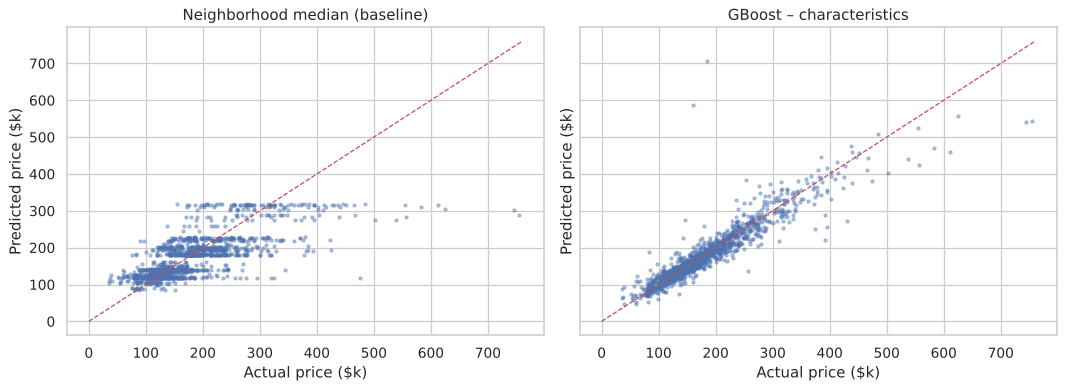

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
for a, n in zip(ax, ["Neighborhood median (baseline)", "GBoost – characteristics"]):
    a.scatter(price / 1000, oof[n] / 1000, s=6, alpha=0.4)
    a.plot([0, 760], [0, 760], "r--", lw=1)
    a.set(xlabel="Actual price ($k)", ylabel="Predicted price ($k)", title=n)
plt.tight_layout(); plt.show()

## 7. Summary for Question 1

- **Answer: yes.** Gradient boosting on property characteristics alone (no location) cuts the cross-validated MAE from about \$36k (neighborhood median) to about \$16k, about 57% lower. It raises R² from 0.51 to 0.85, wins in all 5 folds, is closer than the baseline for 75% of homes, and improves on the baseline in all 25 neighborhoods. Ridge on the same features is also far better on MAE (about \$17k).
- **Adding location** to the characteristics improves things only slightly, so most of what the neighborhood median captures is already reflected in the house itself.
- **Gains are largest** in neighborhoods with mixed housing stock, where one median describes homes poorly.

**Model handed to Q3:** gradient boosting (characteristics only), chosen because it had the lowest CV error on the full data and is robust to unusual sales. With the 4 unusual homes removed, Ridge performs about the same (R² ≈ 0.92 for both). Q3 can therefore compare Ridge coefficients with gradient-boosting permutation importance and call a feature "consistently important" only if both agree.

**Limitations:**
- **No held-out test score:** `test.csv` is unlabeled, so performance comes from 5-fold CV on the training data only.
- **Unusual sales:** a few very large partial sales are badly mispredicted, especially by Ridge. A flagged estimate should be reviewed by a person, not acted on automatically.
- **Random folds, not time-based:** folds mix 2006–2010 sales, so we do not show how the model would do on future sales (for example, after the 2008 housing downturn). Showing that would need a time-based split or newer data.
- **Predictive, not causal:** these results say nothing about what *causes* price (see Q3 for associations).
- **One market:** results cover Ames only.